In [1]:
'''
import iris.quickplot as qplt
import matplotlib.pyplot as plt
import iris.plot as iplt
import matplotlib as mpl
import cartopy.crs as ccrs
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
'''
import glob
import iris
import iris.util
from iris.analysis import MEAN
import numpy as np
from iris.time import PartialDateTime
#import iris.analysis
import iris.coord_categorisation
import warnings
warnings.filterwarnings('ignore')
#stash_list=['m01s34i173', 'm01s34i069',  'm01s34i185', 'm01s34i186',  'm01s34i187']
#stash_map = {'m01s34i173':'CHBr3', 'm01s34i069':'CH2Br2',  'm01s34i185':'CH2BrCl', 'm01s34i186': 'CHBr2Cl',  'm01s34i187':'CHBrCl2'}

#pdt1 = PartialDateTime(year=2010, month=1, day=1)
#pdt2 = PartialDateTime(year=2015, month=12, day=31)
#daterange = iris.Constraint(time=lambda cell: pdt1 <= cell.point < pdt2)


In [2]:
air_mass = iris.load_cube(f'new_mmrs/ord_airmass_2010-2015.nc').collapsed("time", MEAN)
mask = iris.load_cube('new_mmrs/ord_tropo_mask_2010-2015.nc').collapsed("time", MEAN)
volumes = iris.load_cube('/gws/ssde/j25a/ukca/vol1/volume.nc').collapsed("time", MEAN)
areas = iris.load_cube('/gws/ssde/j25a/ukca/vol1/areacella_fx_UKESM1-0-LL_piControl_r1i1p1f2_gn.nc')


In [3]:
def total_burden(mmr, air_mass):
    '''o3_mmr and air_mass are cubes, returns total global O3 burden in kg'''
    burden = air_mass.data*mmr.data
    tot_burden_all = np.sum(burden.data)*(10**-9)
    return tot_burden_all

def trop_mass(mmr, air_mass, mask):
    '''o3_mmr, mask and air_mass are cubes, returns array of tropospheric O3 mass in kg per gridbox'''
    trop_mass = air_mass.data*mmr.data*mask.data
    return trop_mass

def trop_burden(mmr, air_mass):
    '''o3_mmr and air_mass are cubes, returns total global O3 burden in kg'''
    burden = air_mass.data*mmr.data*mask.data
    trop_burden_all = np.sum(burden.data)*(10**-9)
    return trop_burden_all

def yearly_burdens(mmr, tropo_mask = True):
    ''' returns yearly tropospheric burdens for statistcical calculations'''
    iris.coord_categorisation.add_year(mmr, 'time', name='year')
    annual_means = mmr.aggregated_by('year', iris.analysis.MEAN)
    tropo_burdens = []
    for i in range(5):
        year = annual_means[i]
        if tropo_mask:
            tropo_burden = trop_burden(year, air_mass)
        else:
            tropo_burden = total_burden(year, air_mass)
        tropo_burdens = np.append(tropo_burdens, tropo_burden)
    return tropo_burdens

def stdev_burden(mmr):
    year_burd = yearly_burdens(mmr)
    std_value = np.std(year_burd, ddof=1)
    sem_value = np.std(year_burd, ddof=1) / np.sqrt(len(year_burd))
    return std_value, sem_value

### O3 burden

In [4]:
# O3 burden

runs=['iod', 'ord', 'strattrop'] #'NE', 'ord', '10x', 'strattrop', 'roo']
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

tropo_mass = {}
tropo_burden = {}
for run in runs:
    o3_mmr = iris.load_cube(f'new_mmrs/{run}_o3_2010-2015.nc')#.collapsed("time", MEAN)
    time_mean = o3_mmr.collapsed("time", MEAN)
    tropo_mass[run] = trop_mass(time_mean, air_mass, mask)
    tropo_burden[run] = np.sum(trop_mass(time_mean, air_mass, mask).data)*(10**-9) 
    sem_value, std_value = stdev_burden(o3_mmr)
    print("SEM using NumPy:", sem_value, std_value)  
    print(f'{run} tropospheric O3 burden: ', tropo_burden[run], 'Tg')

SEM using NumPy: 5.744650041530782 2.569085599961964
iod tropospheric O3 burden:  313.5284 Tg
SEM using NumPy: 5.56421900522303 2.4883943874749903
ord tropospheric O3 burden:  315.611 Tg
SEM using NumPy: 5.347506391852897 2.391477560459541
strattrop tropospheric O3 burden:  346.43723 Tg


In [ ]:
monthly_tropo_mass = {}
for run in runs:
    o3_mmr = iris.load_cube(f'new_mmrs/{run}_o3_2010-2015.nc')#.collapsed("time", MEAN)
    iris.coord_categorisation.add_month(o3_mmr, 'time', name='month')
    month_means = o3_mmr.aggregated_by(['month'],iris.analysis.MEAN)
    for mon in months:
        one_month = month_means.extract(month=mon)
        monthly_burden = np.sum(trop_mass(one_month, air_mass, mask).data)*(10**-9)

In [52]:
from iris.cube import CubeList

def column_o3_to_DU(trop_mass, areas):
    '''trop_mass is ozone mass for each gridcell, retuns column O3 in DU'''
    sf = (1/0.047997)*(6.02214076*10**23) # 1/molar_mass * Avogado's  to get number of molecules
    tot_trop_mass = np.sum(trop_mass, axis=0) # sum mass in each gridcell over all altitudes
    mass_per_cm = tot_trop_mass/areas.data
    molecules_per_cm = mass_per_cm*sf
    DU = molecules_per_cm/(2.69*10**16)  # molecules_in_one_DU
    return DU

months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

trop_column_o3 = {}
mmrs = {}
cube_list = {}
runs=['ord']#, 'strattrop']
for run in runs:
    cube_list[run] = CubeList([])
    o3_mmr = iris.load_cube(f'new_mmrs/{run}_o3_2010-2015.nc')#.collapsed("longitude", MEAN)
    strattrop_mmr =  iris.load_cube(f'new_mmrs/strattrop_o3_2010-2015.nc')
    for name in ['forecast_period', 'forecast_reference_time']:
        if o3_mmr.coords(name):
            o3_mmr.remove_coord(name)
            strattrop_mmr.remove_coord(name)
    diff_mmr = o3_mmr - strattrop_mmr
    iris.coord_categorisation.add_month(diff_mmr, 'time', name='month')
    month_means = diff_mmr.aggregated_by(['month'],iris.analysis.MEAN)
    trop_column_o3[run] = {}
    for mon in months:
        print(mon)
        one_month = month_means.extract(iris.Constraint(month=mon))
        trop_mass = air_mass.data*one_month.data*mask.data
        all_column_o3 =areas.copy()
        all_column_o3.data = column_o3_to_DU(trop_mass, areas)
        trop_column_o3[run][mon] = all_column_o3.collapsed("longitude", MEAN)
        cube_list[run].append(trop_column_o3[run][mon])
    
print(trop_column_o3['ord']['Jan'])


Jan
Feb
Mar
Apr
May
Jun
Jul
Aug
Sep
Oct
Nov
Dec
cell_area / (m2)                    (latitude: 144)
    Dimension coordinates:
        latitude                             x
    Scalar coordinates:
        longitude                   180.0 degrees, bound=(0.0, 360.0) degrees
    Cell methods:
        0                           area: sum
        1                           longitude: mean
    Attributes:
        Conventions                 'CF-1.7 CMIP-6.2'
        activity_id                 'CMIP'
        branch_method               'standard'
        branch_time_in_child        np.float64(39600.0)
        branch_time_in_parent       np.float64(39600.0)
        cmor_version                '3.4.0'
        comment                     'For atmospheres with more than 1 mesh (e.g., staggered grids), report areas ...'
        creation_date               '2019-07-04T21:31:24Z'
        cv_version                  '6.2.20.1'
        data_specs_version          '01.00.29'
        experiment   

In [53]:

month_cubes = cube_list['ord']

from iris.coords import AuxCoord
from iris.cube import CubeList
import iris.util

for i, c in enumerate(month_cubes, start=1):
    c.add_aux_coord(AuxCoord(i, long_name='month_number', units='1'))

iris.util.equalise_attributes(month_cubes)
cube = CubeList(month_cubes).merge_cube()
print(cube) 

#print(trop_column_o3['ord']['Jan'].shape)

cell_area / (m2)                    (month_number: 12; latitude: 144)
    Dimension coordinates:
        month_number                             x             -
        latitude                                 -             x
    Scalar coordinates:
        longitude                   180.0 degrees, bound=(0.0, 360.0) degrees
    Cell methods:
        0                           area: sum
        1                           longitude: mean
    Attributes:
        Conventions                 'CF-1.7 CMIP-6.2'
        activity_id                 'CMIP'
        branch_method               'standard'
        branch_time_in_child        np.float64(39600.0)
        branch_time_in_parent       np.float64(39600.0)
        cmor_version                '3.4.0'
        comment                     'For atmospheres with more than 1 mesh (e.g., staggered grids), report areas ...'
        creation_date               '2019-07-04T21:31:24Z'
        cv_version                  '6.2.20.1'
        data_sp

(12, 144)


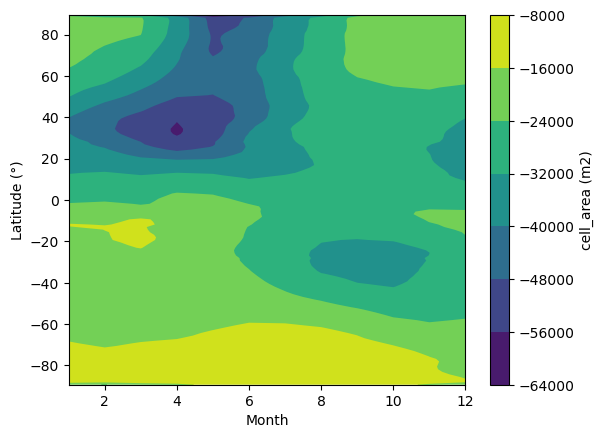

In [55]:
print(cube.data.shape) 
 
cf = iplt.contourf(cube)
plt.colorbar(cf, label=f'{cube.name()} ({cube.units})')
plt.xlabel('Month')
plt.ylabel('Latitude (°)')
plt.show()

ValueError: Cube must be 2-dimensional. Got 1 dimensions.

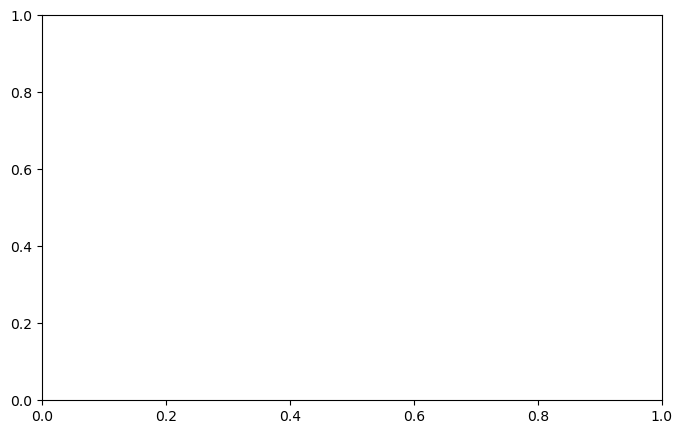

In [40]:
import iris.plot as iplt
import matplotlib.pyplot as plt

cube.transpose()   # optional: puts latitude first so it's on the y axis... see note below

fig, ax = plt.subplots(figsize=(8, 5))
cf = iplt.contourf(cube.coord('month_number'), cube.coord('latitude'), cube.data.T, levels=15)


## CHBr3 & CH2Br2 lifetime

In [7]:
# CHBr3 & CH2Br2 lifetime
runs=['ord', 'roo', 'zis', 'iod']
tropo_mass = {}
spec_list = ['CHBr3','CH2Br2']
fn_map, dir_map = {'ord':'','roo':'_roo','zis':'_ziska', 'iod':''},{'ord':'DEST','roo':'Roo','zis':'Ziska', 'iod':'DEST'}

for spec in spec_list:
    for run in runs:
        mmr = iris.load_cube(f'new_mmrs/{run}_{spec}_2010-2015.nc')#.collapsed("time", MEAN)
        #tot_burden = total_burden(mmr.collapsed("time", MEAN), air_mass)
        
        production_flux = iris.load_cube(f'/home/users/mollym/emission_inventories/{dir_map[run]}_emissions/ukca_emiss_{spec}_DEST_N96{fn_map[run]}.nc').collapsed("time", MEAN)
        burdens_by_year = yearly_burdens(mmr, tropo_mask = False)
        
        tot_prod_Tg = np.sum(production_flux.data*areas.data)*10**-9   
        lifetimes = (burdens_by_year/tot_prod_Tg)/(3600*24)
        sem_value = np.std(lifetimes, ddof=1) / np.sqrt(len(lifetimes))
        print(f'{run} {spec} lifetime: {np.mean(lifetimes)} days {sem_value}')

ord CHBr3 lifetime: 17.847019334752364 days 0.03222802335597995
roo CHBr3 lifetime: 20.75927110902201 days 0.1888867528149137
zis CHBr3 lifetime: 21.990385246275032 days 0.06145671476014114
iod CHBr3 lifetime: 18.626594787984452 days 0.027520728377356505
ord CH2Br2 lifetime: 108.05374878958158 days 0.4808431913342354
roo CH2Br2 lifetime: 110.07186316336345 days 0.7526202968705824
zis CH2Br2 lifetime: 108.56574482686642 days 1.3107212880754469
iod CH2Br2 lifetime: 113.1494707821216 days 0.5730531235432076


## OH airmass weighted average concentrations

In [33]:
# OH airmass weighted average concentrations

for run in runs:
    mmr = iris.load_cube(f'new_mmrs/{run}_OH_2010-2015.nc').collapsed("time", MEAN)
    total_mass_in_troposphere = np.sum(air_mass.data*mmr.data*mask.data)
    total_vol_in_troposphere = np.sum(volumes.data*mask.data)
    density = (total_mass_in_troposphere/total_vol_in_troposphere)*(1/0.017)*(6.02214076*10**23)*(10**-6)*(10**-6)
    print(run, density)
    
    ''' 
    iris.coord_categorisation.add_year(o3_mmr, 'time', name='year')
    annual_means = o3_mmr.aggregated_by('year', iris.analysis.MEAN)
    
    tropo_concentrations = []
    for i in range(5):
        year = annual_means[i]
        tropo_mass[run] = trop_mass(year, air_mass, mask)
        tropo_burden = np.sum(tropo_mass[run])*(10**-9) 
        tot_trop_vol = np.sum(volumes.data*mask.data)
        tropo_conc = (tropo_burden/tot_trop_vol)*(1/0.017)*(6.02214076*10**23)*(10**9)*(10**-6)*(10**-5)  
        tropo_concentrations = np.append(tropo_concentrations, tropo_conc)
    sem_value = np.std(tropo_concentrations, ddof=1) / np.sqrt(len(tropo_concentrations))
    std_value = np.std(tropo_concentrations, ddof=1)
    print("SEM using NumPy:", sem_value, std_value)
    print(f'{run} tropospheric OH conc: ', np.mean(tropo_concentrations), 'molecules/cm3')    
    '''

iod 1.2264646
ord 1.2917706
strattrop 1.3198115


## methane lifetime

In [40]:
# methane lifetime

runs=['zis','strattrop', 'ord', 'iod']#roo', 'zis']#, '10x']

for run in runs:
    mmr = iris.load_cube(f'new_mmrs/{run}_ch4_2010-2015.nc')#.collapsed("time", MEAN)
    ch4_flux = iris.load_cube(f'new_mmrs/{run}_ch4_flux_2010-2015.nc')#.collapsed("time", MEAN)
    iris.coord_categorisation.add_year(ch4_flux, 'time', name='year')
    annual_flux = ch4_flux.aggregated_by('year', iris.analysis.MEAN)
    lifetimes = []
    annual_mean_burdens = yearly_burdens(mmr,tropo_mask = False)
    for i in range(5):
        flux = np.sum(annual_flux[i].data)
        ch4_lifetime = (annual_mean_burdens[i]/(3600*24*365*flux*16.043*10**-12))
        lifetimes = np.append(lifetimes, ch4_lifetime)
    sem_value = np.std(lifetimes, ddof=1) / np.sqrt(len(lifetimes))
    print(f'{run} CHBr3 lifetime: {np.mean(lifetimes)} years {sem_value}')

zis CHBr3 lifetime: 7.96633317244369 years 0.03510234808955588
strattrop CHBr3 lifetime: 7.835179687455624 years 0.0313955002167468
ord CHBr3 lifetime: 8.078941447380597 years 0.03412392133847518
iod CHBr3 lifetime: 8.493880408151606 years 0.038557473787821324
